# COVID-19 Status Prediction

**Developed By:** Wafa Hamdan Alshehri

## Project Overview

This machine learning project aims to predict COVID-19 status using binary symptom, health-condition, and exposure-related indicators.

The project includes data cleaning, exploratory data analysis, class-imbalance handling, model training, and performance evaluation. Logistic Regression, K-Nearest Neighbors, and Decision Tree are compared using an untouched holdout test set and group-aware cross-validation.

## Project Objectives

- Examine the distribution and quality of the dataset.
- Identify symptoms and exposure indicators associated with COVID-19 status.
- Address class imbalance using random oversampling on the training data only.
- Compare the performance of multiple classification models.
- Evaluate the models using accuracy, balanced accuracy, precision, recall, F1-score, macro F1-score, and confusion matrices.

## Dataset

The dataset was obtained from Kaggle and contains binary values representing symptoms, existing health conditions, exposure indicators, and COVID-19 status.

The target variable is `COVID-19`:

- `Yes` indicates a COVID-19 positive record.
- `No` indicates a COVID-19 negative record.

All remaining columns are used as input features.

> **Disclaimer:** This project is intended for educational purposes only and should not be used for medical diagnosis or clinical decision-making.

## Import the necessary libraries

In [1]:
# data processing library

import numpy as np
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# data visualization library

import matplotlib.pyplot as plt
import seaborn as sns

## Importing the Dataset

The dataset is loaded into a Pandas DataFrame named `covid_dataset`.

In [2]:
import io
import zipfile
from urllib.request import urlopen

kaggle_dataset_url = (
    "https://www.kaggle.com/api/v1/datasets/download/"
    "hemanthhari/symptoms-and-covid-presence"
)

with urlopen(
    kaggle_dataset_url,
    timeout=60
) as response:
    dataset_archive = response.read()

with zipfile.ZipFile(
    io.BytesIO(dataset_archive)
) as archive:
    with archive.open(
        "Covid Dataset.csv"
    ) as dataset_file:
        covid_dataset = pd.read_csv(
            dataset_file
        )

covid_dataset.head()

,Breathing Problem,Fever,Dry Cough,Sore throat,Running Nose,Asthma,Chronic Lung Disease,Headache,Heart Disease,Diabetes,...,Fatigue,Gastrointestinal,Abroad travel,Contact with COVID Patient,Attended Large Gathering,Visited Public Exposed Places,Family working in Public Exposed Places,Wearing Masks,Sanitization from Market,COVID-19
0,Yes,Yes,Yes,Yes,Yes,No,No,No,No,Yes,...,Yes,Yes,No,Yes,No,Yes,Yes,No,No,Yes
1,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,No,No,...,Yes,No,No,No,Yes,Yes,No,No,No,Yes
2,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,...,Yes,Yes,Yes,No,No,No,No,No,No,Yes
3,Yes,Yes,Yes,No,No,Yes,No,No,Yes,Yes,...,No,No,Yes,No,Yes,Yes,No,No,No,Yes
4,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,...,No,Yes,No,Yes,No,Yes,No,No,No,Yes


## Dataset Dimensions

The dataset dimensions show the total number of records and features.

In [3]:
rows, columns = covid_dataset.shape

print(f"Number of rows: {rows}")
print(f"Number of columns: {columns}")

Number of rows: 5434
Number of columns: 21


## Dataset Information

In [4]:
# Take a look at the datatypes
covid_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5434 entries, 0 to 5433
Data columns (total 21 columns):
 #   Column                                   Non-Null Count  Dtype 
---  ------                                   --------------  ----- 
 0   Breathing Problem                        5434 non-null   object
 1   Fever                                    5434 non-null   object
 2   Dry Cough                                5434 non-null   object
 3   Sore throat                              5434 non-null   object
 4   Running Nose                             5434 non-null   object
 5   Asthma                                   5434 non-null   object
 6   Chronic Lung Disease                     5434 non-null   object
 7   Headache                                 5434 non-null   object
 8   Heart Disease                            5434 non-null   object
 9   Diabetes                                 5434 non-null   object
 10  Hyper Tension                            5434 non-null   obj

## Inspecting Column Names

Some column names contain leading or trailing spaces that should be removed before analysis.

In [5]:
covid_dataset.columns.tolist()

['Breathing Problem',
 'Fever',
 'Dry Cough',
 'Sore throat',
 'Running Nose',
 'Asthma',
 'Chronic Lung Disease',
 'Headache',
 'Heart Disease',
 'Diabetes',
 'Hyper Tension',
 'Fatigue ',
 'Gastrointestinal ',
 'Abroad travel',
 'Contact with COVID Patient',
 'Attended Large Gathering',
 'Visited Public Exposed Places',
 'Family working in Public Exposed Places',
 'Wearing Masks',
 'Sanitization from Market',
 'COVID-19']

## Data Preparation

A separate copy of the dataset is created to preserve the original data. Extra spaces are removed from column names, and binary values are converted from `Yes/No` to `1/0`.


In [6]:
# Create a separate copy for exploratory data analysis
eda_df = covid_dataset.copy()

# Remove extra spaces from column names
eda_df.columns = eda_df.columns.str.strip()

# Convert binary Yes/No values into 1/0
binary_mapping = {
    "No": 0,
    "Yes": 1
}

eda_df = eda_df.apply(
    lambda column: (
        column.map(binary_mapping)
        if column.dtype == "object"
        else column
    )
)

eda_df.head()


,Breathing Problem,Fever,Dry Cough,Sore throat,Running Nose,Asthma,Chronic Lung Disease,Headache,Heart Disease,Diabetes,...,Fatigue,Gastrointestinal,Abroad travel,Contact with COVID Patient,Attended Large Gathering,Visited Public Exposed Places,Family working in Public Exposed Places,Wearing Masks,Sanitization from Market,COVID-19
0,1,1,1,1,1,0,0,0,0,1,...,1,1,0,1,0,1,1,0,0,1
1,1,1,1,1,0,1,1,1,0,0,...,1,0,0,0,1,1,0,0,0,1
2,1,1,1,1,1,1,1,1,0,1,...,1,1,1,0,0,0,0,0,0,1
3,1,1,1,0,0,1,0,0,1,1,...,0,0,1,0,1,1,0,0,0,1
4,1,1,1,1,1,0,1,1,1,1,...,0,1,0,1,0,1,0,0,0,1


## Data After Transformation

In [7]:
eda_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5434 entries, 0 to 5433
Data columns (total 21 columns):
 #   Column                                   Non-Null Count  Dtype
---  ------                                   --------------  -----
 0   Breathing Problem                        5434 non-null   int64
 1   Fever                                    5434 non-null   int64
 2   Dry Cough                                5434 non-null   int64
 3   Sore throat                              5434 non-null   int64
 4   Running Nose                             5434 non-null   int64
 5   Asthma                                   5434 non-null   int64
 6   Chronic Lung Disease                     5434 non-null   int64
 7   Headache                                 5434 non-null   int64
 8   Heart Disease                            5434 non-null   int64
 9   Diabetes                                 5434 non-null   int64
 10  Hyper Tension                            5434 non-null   int64
 11  Fati

In [8]:
eda_df.head().T

,0,1,2,3,4
Breathing Problem,1,1,1,1,1
Fever,1,1,1,1,1
Dry Cough,1,1,1,1,1
Sore throat,1,1,1,0,1
Running Nose,1,0,1,0,1
Asthma,0,1,1,1,0
Chronic Lung Disease,0,1,1,0,1
Headache,0,1,1,0,1
Heart Disease,0,0,0,1,1
Diabetes,1,0,1,1,1


## Descriptive Statistics

Descriptive statistics provide a summary of the distribution of each binary feature.

In [9]:
eda_df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Breathing Problem,5434.0,0.666,0.472,0.0,0.0,1.0,1.0,1.0
Fever,5434.0,0.786,0.410,0.0,1.0,1.0,1.0,1.0
Dry Cough,5434.0,0.793,0.405,0.0,1.0,1.0,1.0,1.0
Sore throat,5434.0,0.727,0.445,0.0,0.0,1.0,1.0,1.0
Running Nose,5434.0,0.543,0.498,0.0,0.0,1.0,1.0,1.0
Asthma,5434.0,0.463,0.499,0.0,0.0,0.0,1.0,1.0
Chronic Lung Disease,5434.0,0.472,0.499,0.0,0.0,0.0,1.0,1.0
Headache,5434.0,0.503,0.500,0.0,0.0,1.0,1.0,1.0
Heart Disease,5434.0,0.464,0.499,0.0,0.0,0.0,1.0,1.0
Diabetes,5434.0,0.476,0.499,0.0,0.0,0.0,1.0,1.0


## Missing Values

Missing values are checked to determine whether additional data cleaning is required.

In [10]:
# Count missing values in each column
missing_values = eda_df.isnull().sum()

# Calculate the missing-value percentage
missing_percentage = (
    missing_values / len(eda_df) * 100
)

# Create a missing-values summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": missing_percentage
})

# Sort the table from the highest to the lowest number of missing values
missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

missing_summary

,Missing Values,Missing Percentage (%)
Breathing Problem,0,0.0
Fever,0,0.0
Dry Cough,0,0.0
Sore throat,0,0.0
Running Nose,0,0.0
Asthma,0,0.0
Chronic Lung Disease,0,0.0
Headache,0,0.0
Heart Disease,0,0.0
Diabetes,0,0.0


In [11]:
total_missing = missing_values.sum()

print(f"Total missing values: {total_missing}")

Total missing values: 0


The dataset contains no missing values; therefore, no missing-value treatment is required.

## Duplicate Records

Duplicate records are examined before modeling. Because the dataset contains binary symptoms and indicators, identical feature combinations may represent valid separate observations and should not be removed automatically.

In [12]:
duplicate_rows = eda_df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_rows}")

Number of duplicate rows: 4968


# Exploratory Data Analysis

This section explores the target distribution and the relationships between the dataset features and COVID-19 status.

In [13]:
# Apply a consistent professional style
sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams.update({
    "figure.dpi": 120,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10
})

# Project color palette
NAVY = "#17324D"
TEAL = "#2A9D8F"
GOLD = "#E9C46A"
CORAL = "#E76F51"

## COVID-19 Class Distribution

The target distribution is examined to determine whether the dataset is balanced.

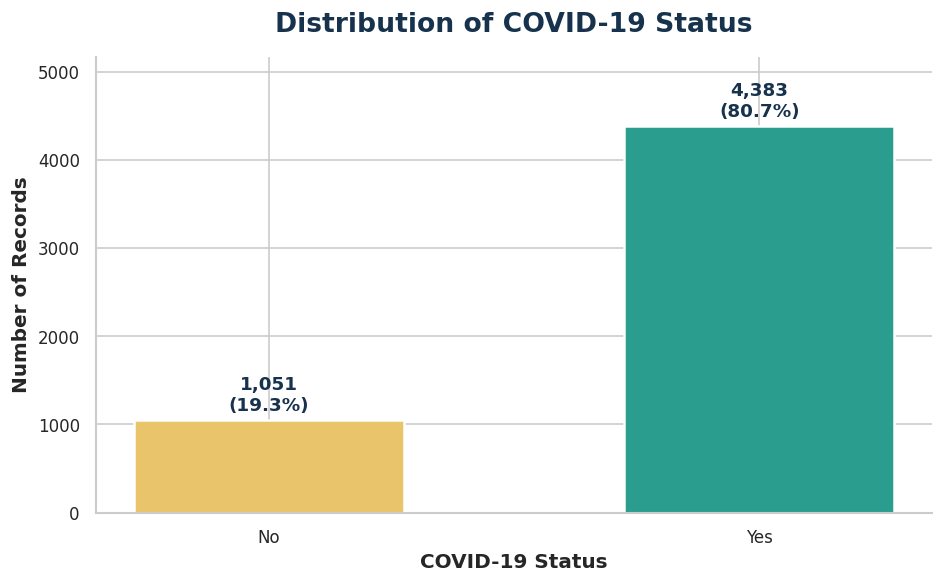

In [14]:
class_counts = (
    eda_df["COVID-19"]
    .value_counts()
    .reindex([0, 1])
)

class_labels = ["No", "Yes"]
class_colors = [GOLD, TEAL]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    class_labels,
    class_counts.values,
    color=class_colors,
    width=0.55,
    edgecolor="white",
    linewidth=1.5
)

total_records = class_counts.sum()

for bar, count in zip(bars, class_counts.values):
    percentage = count / total_records * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 60,
        f"{count:,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=NAVY
    )

ax.set_title(
    "Distribution of COVID-19 Status",
    color=NAVY,
    pad=15
)

ax.set_xlabel("COVID-19 Status")
ax.set_ylabel("Number of Records")
ax.set_ylim(0, class_counts.max() * 1.18)

sns.despine()
plt.tight_layout()
plt.show()

The target variable is imbalanced. COVID-19 positive records represent the majority of the dataset, while negative records represent the minority class. This imbalance should be considered during model training and evaluation.

## Feature Prevalence by COVID-19 Status

The prevalence of each binary feature is compared between COVID-19 positive and negative records.

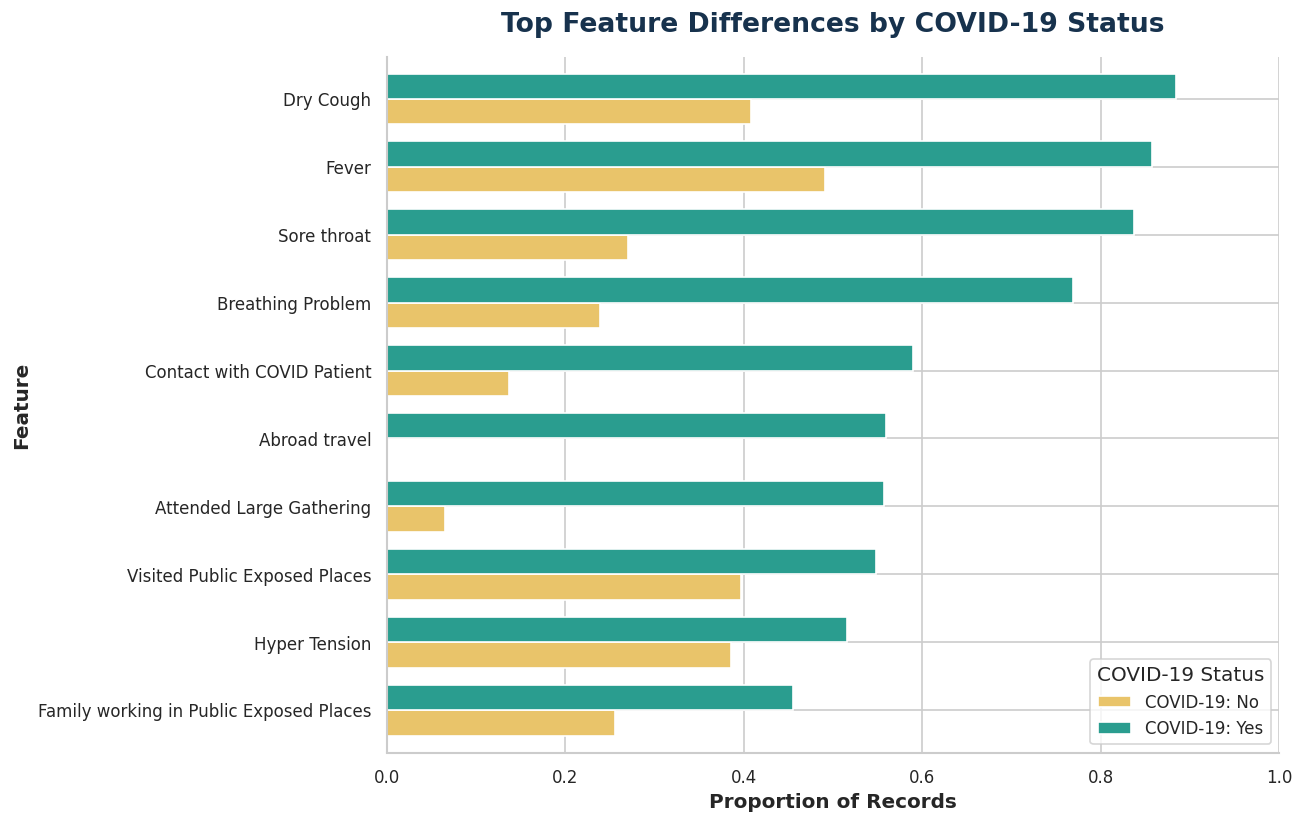

In [15]:
# Calculate feature prevalence within each target class
feature_prevalence = (
    eda_df
    .groupby("COVID-19")
    .mean()
    .T
)

# Display meaningful labels instead of 0 and 1
feature_prevalence.columns = [
    "COVID-19: No",
    "COVID-19: Yes"
]

# Calculate the difference between the two classes
feature_prevalence["Absolute Difference"] = (
    feature_prevalence["COVID-19: Yes"]
    - feature_prevalence["COVID-19: No"]
).abs()

# Select the ten features with the largest differences
top_features = (
    feature_prevalence
    .nlargest(
        10,
        "Absolute Difference"
    )
    .index
)

plot_data = (
    feature_prevalence
    .loc[
        top_features,
        ["COVID-19: No", "COVID-19: Yes"]
    ]
    .sort_values(
        by="COVID-19: Yes"
    )
)

ax = plot_data.plot(
    kind="barh",
    figsize=(11, 7),
    color=[GOLD, TEAL],
    width=0.75,
    edgecolor="white"
)

ax.set_title(
    "Top Feature Differences by COVID-19 Status",
    color=NAVY,
    pad=15
)

ax.set_xlabel("Proportion of Records")
ax.set_ylabel("Feature")
ax.set_xlim(0, 1)

ax.legend(
    title="COVID-19 Status",
    loc="lower right",
    frameon=True
)

sns.despine()
plt.tight_layout()
plt.show()

The chart highlights features with the largest differences between COVID-19 positive and negative records. These results represent associations within this dataset and should not be interpreted as causal relationships.

## Correlation with COVID-19 Status

The features with the strongest correlations with the target variable are displayed below.

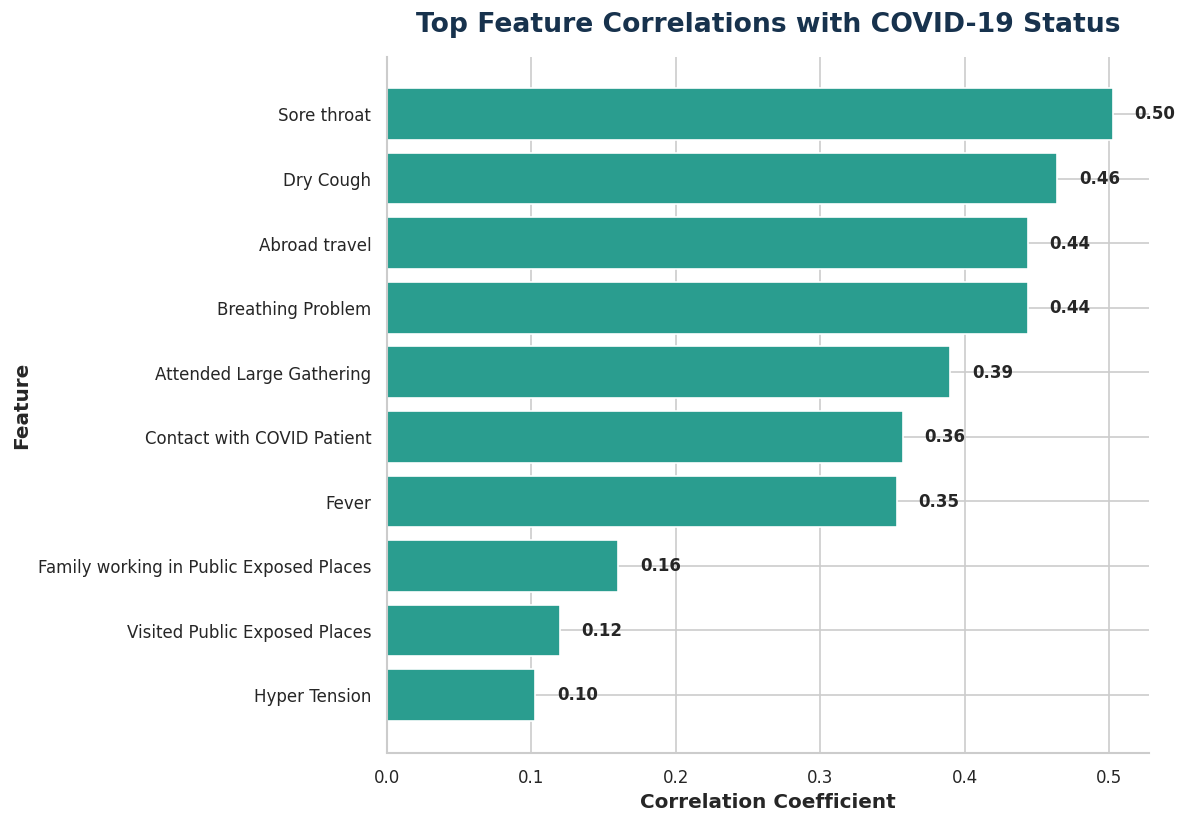

In [16]:
target_correlations = (
    eda_df
    .corr(numeric_only=True)["COVID-19"]
    .drop("COVID-19")
    .sort_values(
        key=abs,
        ascending=False
    )
    .head(10)
    .sort_values()
)

bar_colors = [
    TEAL if value >= 0 else CORAL
    for value in target_correlations.values
]

fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    target_correlations.index,
    target_correlations.values,
    color=bar_colors,
    edgecolor="white"
)

for bar, value in zip(
    bars,
    target_correlations.values
):
    position = (
        value + 0.015
        if value >= 0
        else value - 0.015
    )

    alignment = (
        "left"
        if value >= 0
        else "right"
    )

    ax.text(
        position,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        ha=alignment,
        fontsize=10,
        fontweight="bold"
    )

ax.axvline(
    0,
    color=NAVY,
    linewidth=1
)

ax.set_title(
    "Top Feature Correlations with COVID-19 Status",
    color=NAVY,
    pad=15
)

ax.set_xlabel("Correlation Coefficient")
ax.set_ylabel("Feature")

sns.despine()
plt.tight_layout()
plt.show()

The chart displays the features with the strongest associations with COVID-19 status. Correlation is used for exploratory analysis and does not demonstrate causation.

## Correlation Heatmap

The heatmap examines the relationships among the features most strongly associated with COVID-19 status.

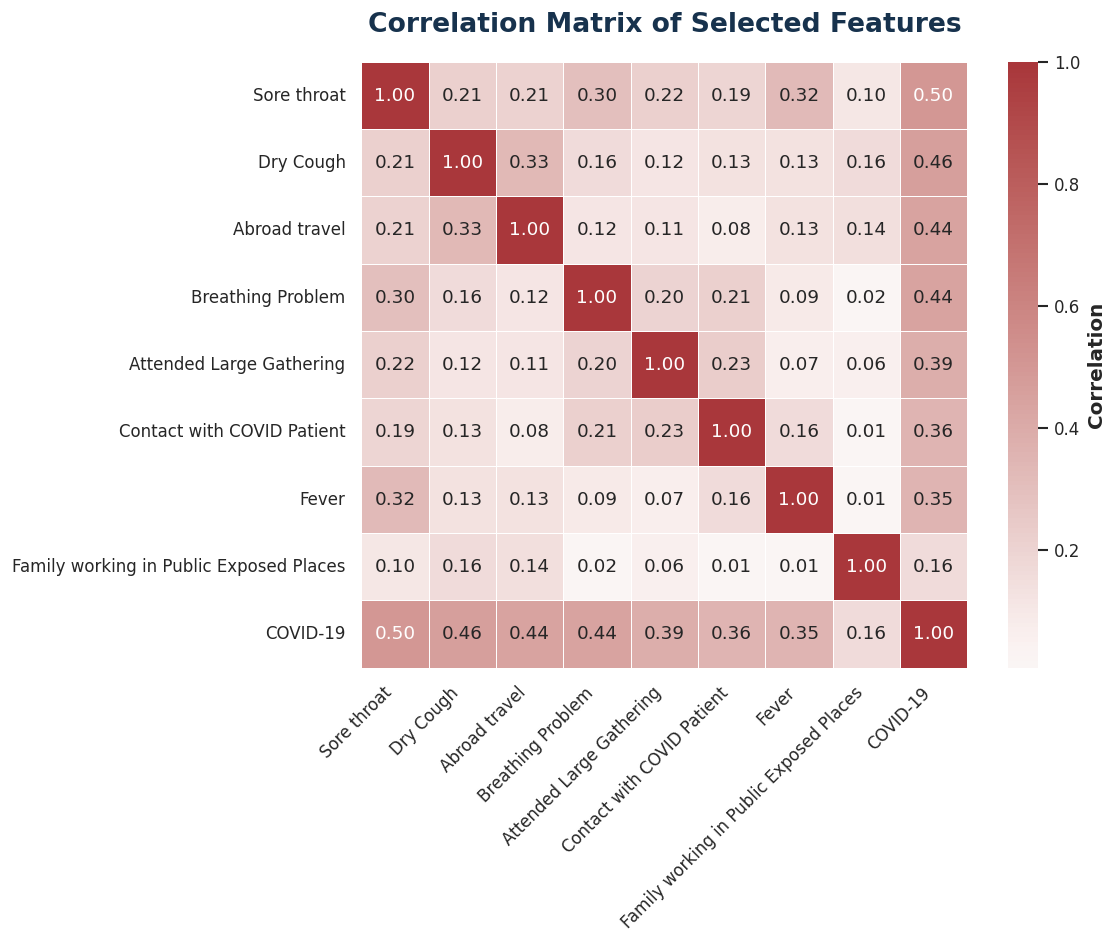

In [17]:
# Select the eight strongest features
important_features = (
    eda_df
    .corr(numeric_only=True)["COVID-19"]
    .drop("COVID-19")
    .abs()
    .sort_values(ascending=False)
    .head(8)
    .index
    .tolist()
)

heatmap_columns = (
    important_features
    + ["COVID-19"]
)

correlation_matrix = (
    eda_df[heatmap_columns]
    .corr(numeric_only=True)
)

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    linewidths=0.6,
    linecolor="white",
    square=True,
    cbar_kws={
        "label": "Correlation"
    },
    ax=ax
)

ax.set_title(
    "Correlation Matrix of Selected Features",
    color=NAVY,
    pad=18
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

The heatmap shows the relationships among the selected features and COVID-19 status. Correlation values represent statistical associations and should not be interpreted as causal effects.

# Handling Class Imbalance

The dataset contains an imbalanced target variable and a high number of repeated feature patterns. A stratified group-based split is used to keep identical feature patterns within the same data partition. Random oversampling is then applied only to the training data, while the test data remains unchanged.

In [18]:
# Separate the input features from the target variable
X = eda_df.drop(
    "COVID-19",
    axis=1
)

y = eda_df["COVID-19"]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

print("\nOriginal class distribution:")
print(
    y.value_counts()
    .rename(index={
        0: "No",
        1: "Yes"
    })
)

Features shape: (5434, 20)
Target shape: (5434,)

Original class distribution:
COVID-19
Yes    4383
No     1051
Name: count, dtype: int64


## Group Identification

Rows with identical feature values are assigned to the same group to prevent the same feature pattern from appearing in both the training and test sets.

In [19]:
# Assign identical feature patterns to the same group
groups = pd.util.hash_pandas_object(
    X,
    index=False
)

print(
    "Number of unique feature patterns:",
    groups.nunique()
)

Number of unique feature patterns: 453


## Training and Test Split

A stratified group-based split is used to create an approximately 80% training set and 20% test set while preventing identical feature patterns from appearing in both sets.

In [20]:
from sklearn.model_selection import StratifiedGroupKFold

group_split = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_index, test_index = next(
    group_split.split(
        X,
        y,
        groups=groups
    )
)

X_train = X.iloc[train_index].copy()
X_test = X.iloc[test_index].copy()

y_train = y.iloc[train_index].copy()
y_test = y.iloc[test_index].copy()

print(f"Training features: {X_train.shape}")
print(f"Testing features: {X_test.shape}")

print("\nTraining class distribution:")
print(
    y_train.value_counts()
    .rename(index={
        0: "No",
        1: "Yes"
    })
)

print("\nTesting class distribution:")
print(
    y_test.value_counts()
    .rename(index={
        0: "No",
        1: "Yes"
    })
)

Training features: (4402, 20)
Testing features: (1032, 20)

Training class distribution:
COVID-19
Yes    3626
No      776
Name: count, dtype: int64

Testing class distribution:
COVID-19
Yes    757
No     275
Name: count, dtype: int64


In [21]:
# Verify that no feature patterns overlap between the datasets
training_group_ids = set(
    groups.iloc[train_index]
)

testing_group_ids = set(
    groups.iloc[test_index]
)

group_overlap = (
    training_group_ids
    .intersection(testing_group_ids)
)

print(
    "Number of shared feature patterns:",
    len(group_overlap)
)

Number of shared feature patterns: 0


No identical feature patterns are shared between the training and test sets, reducing the risk of overly optimistic evaluation results caused by repeated records.

## Random Oversampling

Random oversampling is applied exclusively to the training set to balance the target classes. The test set is preserved in its original distribution to provide a realistic evaluation.

In [22]:
from imblearn.over_sampling import RandomOverSampler

oversampler = RandomOverSampler(
    random_state=42
)

X_train_resampled, y_train_resampled = (
    oversampler.fit_resample(
        X_train,
        y_train
    )
)

print("Training distribution before oversampling:")
print(
    y_train.value_counts()
    .rename(index={
        0: "No",
        1: "Yes"
    })
)

print("\nTraining distribution after oversampling:")
print(
    y_train_resampled.value_counts()
    .rename(index={
        0: "No",
        1: "Yes"
    })
)

print("\nTest distribution remains unchanged:")
print(
    y_test.value_counts()
    .rename(index={
        0: "No",
        1: "Yes"
    })
)

Training distribution before oversampling:
COVID-19
Yes    3626
No      776
Name: count, dtype: int64

Training distribution after oversampling:
COVID-19
Yes    3626
No     3626
Name: count, dtype: int64

Test distribution remains unchanged:
COVID-19
Yes    757
No     275
Name: count, dtype: int64


## Training Class Distribution Before and After Oversampling

The following charts compare the training class distribution before and after applying random oversampling.

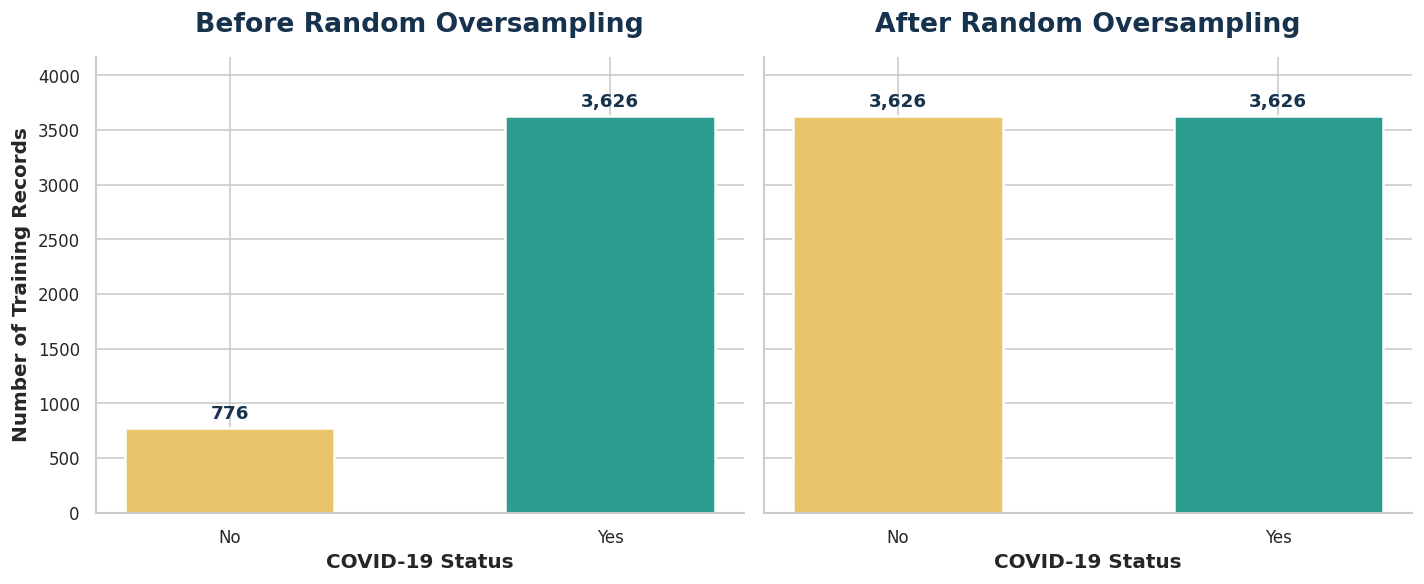

In [23]:
before_oversampling = (
    y_train
    .value_counts()
    .reindex([0, 1])
)

after_oversampling = (
    y_train_resampled
    .value_counts()
    .reindex([0, 1])
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5),
    sharey=True
)

class_labels = ["No", "Yes"]
class_colors = [GOLD, TEAL]

distributions = [
    (
        before_oversampling,
        "Before Random Oversampling"
    ),
    (
        after_oversampling,
        "After Random Oversampling"
    )
]

maximum_count = after_oversampling.max()

for axis, (counts, title) in zip(
    axes,
    distributions
):
    bars = axis.bar(
        class_labels,
        counts.values,
        color=class_colors,
        width=0.55,
        edgecolor="white",
        linewidth=1.5
    )

    for bar, count in zip(
        bars,
        counts.values
    ):
        axis.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 50,
            f"{count:,}",
            ha="center",
            va="bottom",
            fontweight="bold",
            color=NAVY
        )

    axis.set_title(
        title,
        color=NAVY,
        pad=15
    )

    axis.set_xlabel("COVID-19 Status")
    axis.set_ylim(0, maximum_count * 1.15)

axes[0].set_ylabel("Number of Training Records")

sns.despine()
plt.tight_layout()
plt.show()

Random oversampling balanced the two target classes in the training data. The test data was not resampled and retains its original class distribution.

# Model Development and Evaluation

Three classification models are evaluated: Logistic Regression, K-Nearest Neighbors, and Decision Tree. The models are trained using the balanced training data and evaluated using the original test data.

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_score,
    cross_validate
)

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline

## Selecting the Number of Neighbors for KNN

The number of neighbors is selected using group-aware cross-validation on the training data. The F1-score is used because the original target distribution is imbalanced.

In [25]:
# Keep the training groups aligned with the training records
training_groups = groups.iloc[train_index]

# Create a group-aware cross-validation strategy
knn_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

k_values = range(1, 31)
mean_f1_scores = []

for k in k_values:

    knn_pipeline = Pipeline([
        (
            "oversampling",
            RandomOverSampler(
                random_state=42
            )
        ),
        (
            "model",
            KNeighborsClassifier(
                n_neighbors=k
            )
        )
    ])

    k_scores = cross_val_score(
        knn_pipeline,
        X_train,
        y_train,
        groups=training_groups,
        cv=knn_cv,
        scoring="f1",
        n_jobs=-1
    )

    mean_f1_scores.append(
        k_scores.mean()
    )

best_k = list(k_values)[
    int(np.argmax(mean_f1_scores))
]

best_k_score = max(mean_f1_scores)

print(
    f"Best number of neighbors: {best_k}"
)

print(
    f"Best mean cross-validation F1-score: "
    f"{best_k_score:.4f}"
)


Best number of neighbors: 3
Best mean cross-validation F1-score: 0.9279


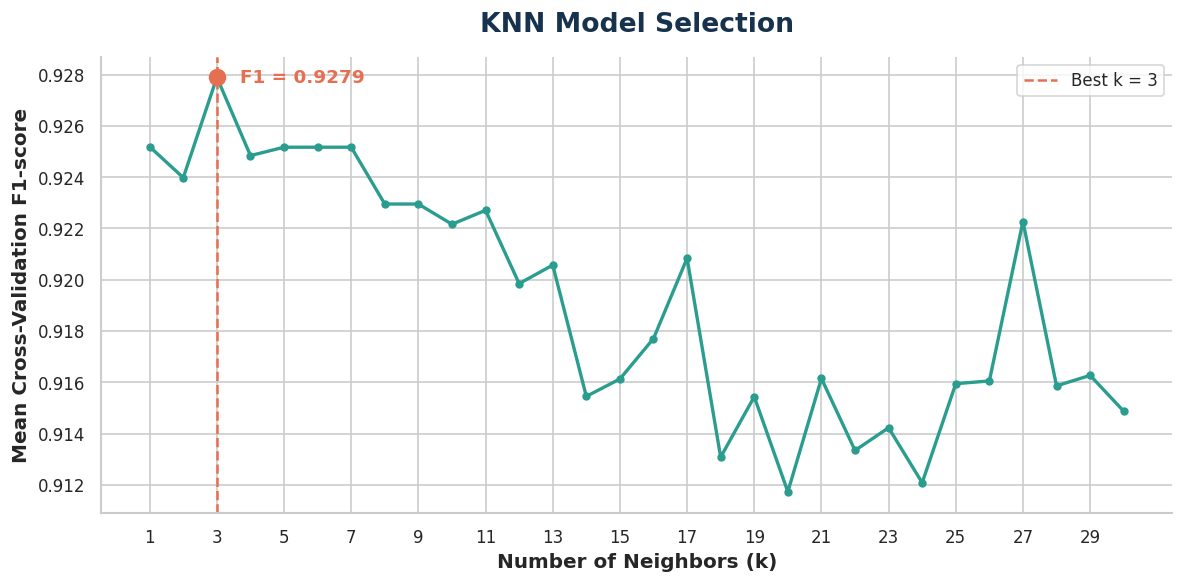

In [26]:
fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    list(k_values),
    mean_f1_scores,
    color=TEAL,
    marker="o",
    markersize=4,
    linewidth=2
)

ax.axvline(
    best_k,
    color=CORAL,
    linestyle="--",
    linewidth=1.5,
    label=f"Best k = {best_k}"
)

ax.scatter(
    best_k,
    best_k_score,
    color=CORAL,
    s=90,
    zorder=3
)

ax.text(
    best_k + 0.7,
    best_k_score,
    f"F1 = {best_k_score:.4f}",
    color=CORAL,
    fontweight="bold",
    va="center"
)

ax.set_title(
    "KNN Model Selection",
    color=NAVY,
    pad=15
)

ax.set_xlabel("Number of Neighbors (k)")
ax.set_ylabel("Mean Cross-Validation F1-score")
ax.set_xticks(range(1, 31, 2))

ax.legend()

sns.despine()
plt.tight_layout()
plt.show()

In [27]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=best_k
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

In [28]:
# Train and evaluate the models
test_results = []
trained_models = {}
model_predictions = {}

for model_name, model in models.items():

    # Train the model using the balanced training data
    model.fit(
        X_train_resampled,
        y_train_resampled
    )

    # Predict the original test data
    predictions = model.predict(
        X_test
    )

    trained_models[model_name] = model
    model_predictions[model_name] = predictions

    test_results.append({
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "F1-score": f1_score(
            y_test,
            predictions,
            zero_division=0
        )
    })

test_results_df = pd.DataFrame(
    test_results
)

test_results_df = (
    test_results_df
    .sort_values(
        by="F1-score",
        ascending=False
    )
    .reset_index(drop=True)
)

test_results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.9331,0.9247,0.9894,0.9560
1,Logistic Regression,0.9099,0.9840,0.8917,0.9356
2,KNN,0.8430,0.9059,0.8771,0.8913


The Decision Tree achieved the highest holdout F1-score and recall, while Logistic Regression achieved the highest precision. KNN produced lower overall performance compared with the other two models. Cross-validation is conducted next to assess whether these results remain consistent across different data partitions.

## Holdout Test Performance

The models are compared using accuracy, precision, recall, and F1-score on the original untouched test data.

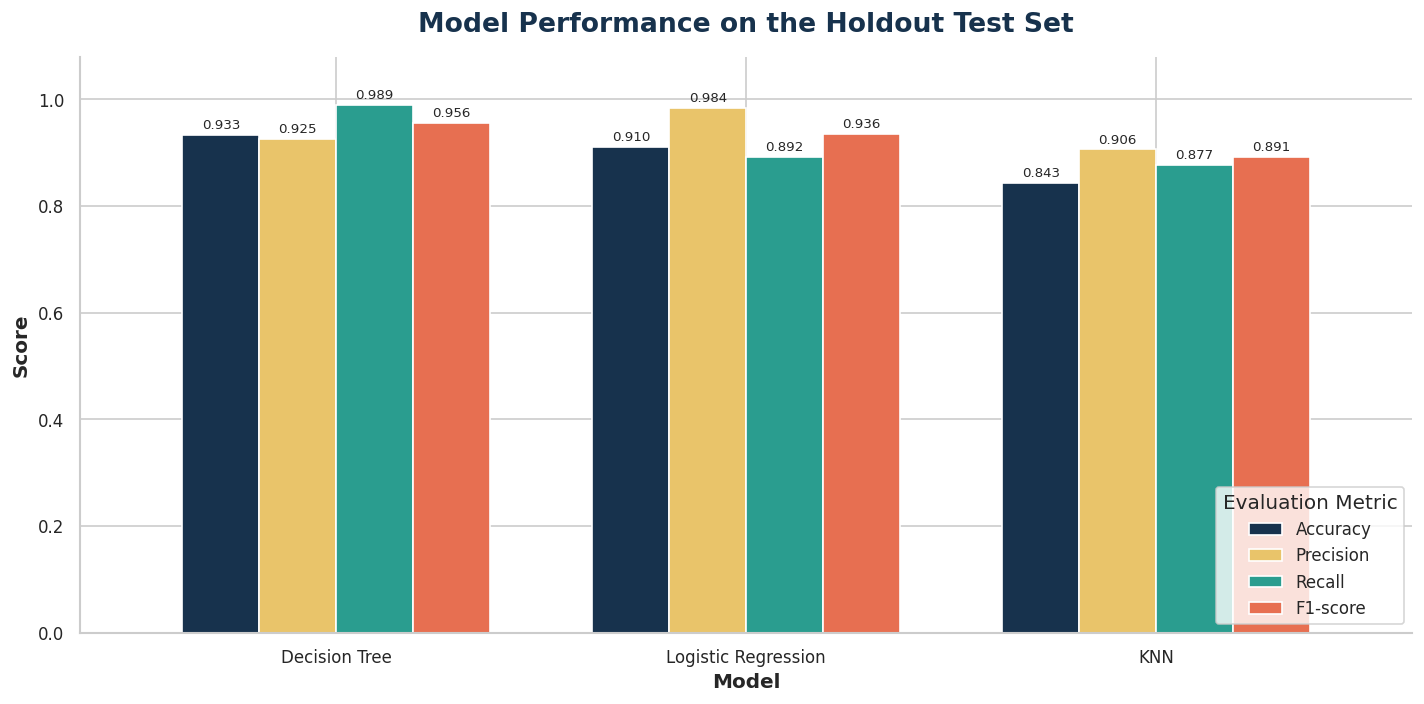

In [29]:
plot_results = (
    test_results_df
    .set_index("Model")
)

ax = plot_results.plot(
    kind="bar",
    figsize=(12, 6),
    color=[
        NAVY,
        GOLD,
        TEAL,
        CORAL
    ],
    width=0.75,
    edgecolor="white"
)

ax.set_title(
    "Model Performance on the Holdout Test Set",
    color=NAVY,
    pad=15
)

ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.08)

plt.xticks(
    rotation=0
)

ax.legend(
    title="Evaluation Metric",
    loc="lower right"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=2,
        fontsize=8
    )

sns.despine()
plt.tight_layout()
plt.show()

## Confusion Matrices

The confusion matrices show the correct and incorrect predictions produced by each model for both target classes.

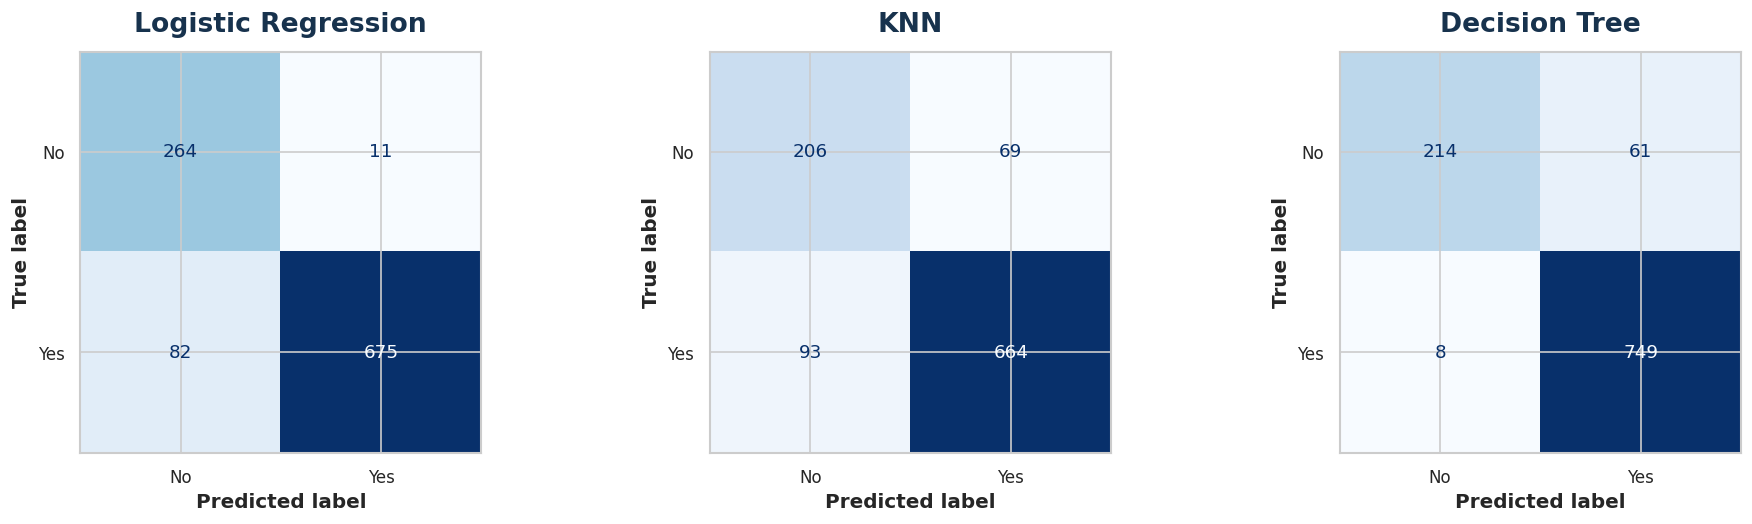

In [30]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 4.5)
)

for axis, model_name in zip(
    axes,
    models.keys()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        model_predictions[model_name],
        display_labels=["No", "Yes"],
        cmap="Blues",
        colorbar=False,
        ax=axis
    )

    axis.set_title(
        model_name,
        color=NAVY,
        pad=12
    )

plt.tight_layout()
plt.show()

## Classification Reports

The classification reports provide class-level precision, recall, and F1-score for each model.

In [31]:
for model_name in models.keys():

    print("=" * 65)
    print(model_name)
    print("=" * 65)

    print(
        classification_report(
            y_test,
            model_predictions[model_name],
            target_names=["No", "Yes"],
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

          No       0.76      0.96      0.85       275
         Yes       0.98      0.89      0.94       757

    accuracy                           0.91      1032
   macro avg       0.87      0.93      0.89      1032
weighted avg       0.93      0.91      0.91      1032

KNN
              precision    recall  f1-score   support

          No       0.69      0.75      0.72       275
         Yes       0.91      0.88      0.89       757

    accuracy                           0.84      1032
   macro avg       0.80      0.81      0.80      1032
weighted avg       0.85      0.84      0.85      1032

Decision Tree
              precision    recall  f1-score   support

          No       0.96      0.78      0.86       275
         Yes       0.92      0.99      0.96       757

    accuracy                           0.93      1032
   macro avg       0.94      0.88      0.91      1032
weighted avg       0.94      0.93   

## Holdout Evaluation Summary

The Decision Tree achieved the strongest overall holdout performance, with an accuracy of 93.31% and an F1-score of 95.60% for the positive class. It correctly identified 749 of the 757 COVID-19 positive records and missed only 8 positive cases.

Logistic Regression achieved the highest precision for the positive class at 98%, but its recall was lower because it missed 82 positive cases. KNN produced the lowest overall performance among the three models.

Because the target classes are imbalanced, the macro-average F1-score is also considered. Decision Tree achieved the highest macro-average F1-score of 91%, followed by Logistic Regression at 89% and KNN at 80%.

These holdout results are validated next using group-aware cross-validation.

## Group-Aware Cross-Validation

Ten-fold stratified group cross-validation is used to evaluate model stability. Random oversampling is performed only within the training portion of each fold.

In [32]:
model_cv = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

scoring_metrics = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "macro_f1": "f1_macro"
}

cv_results = []

for model_name, model in models.items():

    evaluation_pipeline = Pipeline([
        (
            "oversampling",
            RandomOverSampler(
                random_state=42
            )
        ),
        (
            "model",
            model
        )
    ])

    scores = cross_validate(
        evaluation_pipeline,
        X_train,
        y_train,
        groups=training_groups,
        cv=model_cv,
        scoring=scoring_metrics,
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,

        "Mean CV Accuracy": (
            scores["test_accuracy"].mean()
        ),

        "Mean CV Balanced Accuracy": (
            scores[
                "test_balanced_accuracy"
            ].mean()
        ),

        "Mean CV Precision": (
            scores["test_precision"].mean()
        ),

        "Mean CV Recall": (
            scores["test_recall"].mean()
        ),

        "Mean CV F1-score": (
            scores["test_f1"].mean()
        ),

        "Mean CV Macro F1-score": (
            scores["test_macro_f1"].mean()
        )
    })

cv_results_df = pd.DataFrame(
    cv_results
)

cv_results_df = (
    cv_results_df
    .sort_values(
        by="Mean CV Macro F1-score",
        ascending=False
    )
    .reset_index(drop=True)
)

cv_results_df.round(4)

,Model,Mean CV Accuracy,Mean CV Balanced Accuracy,Mean CV Precision,Mean CV Recall,Mean CV F1-score,Mean CV Macro F1-score
0,Decision Tree,0.9524,0.8961,0.9586,0.9825,0.9702,0.9091
1,Logistic Regression,0.9398,0.9280,0.9735,0.9505,0.9616,0.8967
2,KNN,0.8764,0.7823,0.9230,0.9295,0.9237,0.7764


## Cross-Validation Performance

The following chart compares the models using mean accuracy, balanced accuracy, and macro F1-score across the cross-validation folds.

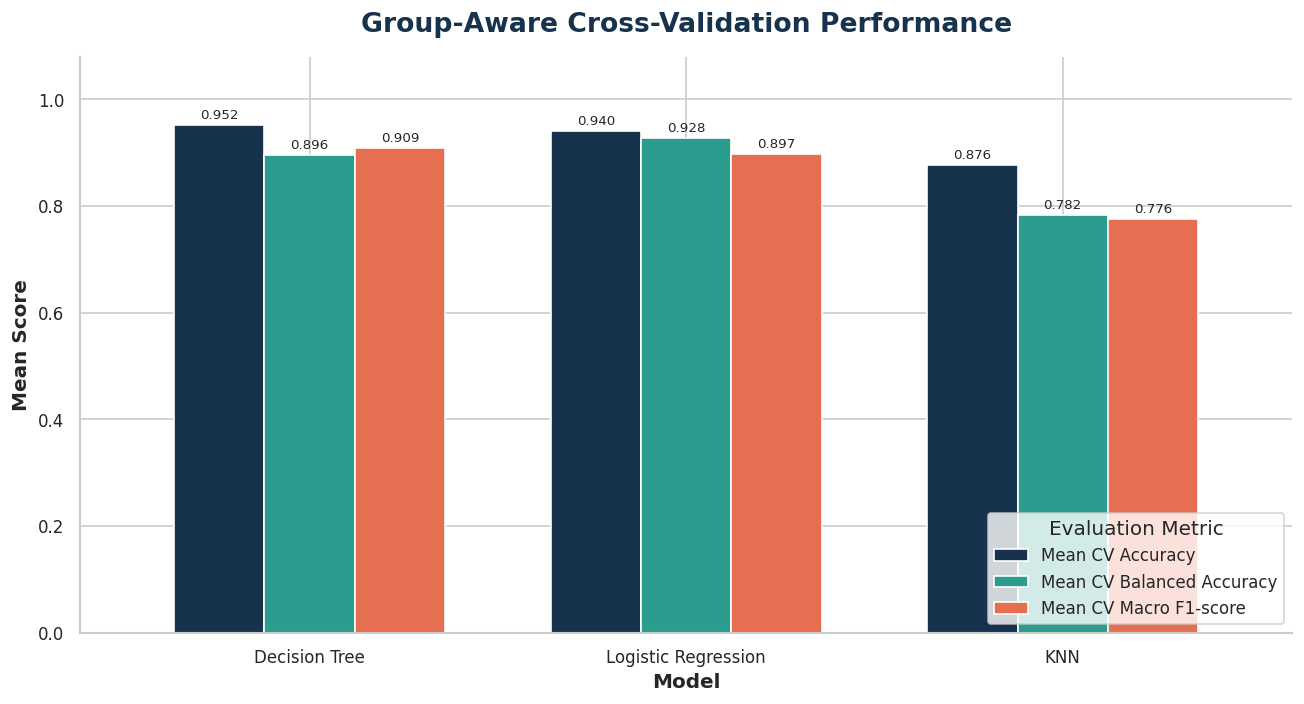

In [33]:
cv_plot_data = (
    cv_results_df
    .set_index("Model")
    [[
        "Mean CV Accuracy",
        "Mean CV Balanced Accuracy",
        "Mean CV Macro F1-score"
    ]]
)

ax = cv_plot_data.plot(
    kind="bar",
    figsize=(11, 6),
    color=[
        NAVY,
        TEAL,
        CORAL
    ],
    width=0.72,
    edgecolor="white"
)

ax.set_title(
    "Group-Aware Cross-Validation Performance",
    color=NAVY,
    pad=15
)

ax.set_xlabel("Model")
ax.set_ylabel("Mean Score")
ax.set_ylim(0, 1.08)

plt.xticks(
    rotation=0
)

ax.legend(
    title="Evaluation Metric",
    loc="lower right"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=2,
        fontsize=8
    )

sns.despine()
plt.tight_layout()
plt.show()

In [34]:
# Identify the best-performing model for each evaluation metric

best_accuracy_model = cv_results_df.loc[
    cv_results_df[
        "Mean CV Accuracy"
    ].idxmax()
]

best_balanced_model = cv_results_df.loc[
    cv_results_df[
        "Mean CV Balanced Accuracy"
    ].idxmax()
]

best_macro_f1_model = cv_results_df.loc[
    cv_results_df[
        "Mean CV Macro F1-score"
    ].idxmax()
]

print(
    "Highest mean accuracy:",
    best_accuracy_model["Model"],
    f'({best_accuracy_model["Mean CV Accuracy"]:.4f})'
)

print(
    "Highest mean balanced accuracy:",
    best_balanced_model["Model"],
    f'({best_balanced_model["Mean CV Balanced Accuracy"]:.4f})'
)

print(
    "Highest mean macro F1-score:",
    best_macro_f1_model["Model"],
    f'({best_macro_f1_model["Mean CV Macro F1-score"]:.4f})'
)

Highest mean accuracy: Decision Tree (0.9524)
Highest mean balanced accuracy: Logistic Regression (0.9280)
Highest mean macro F1-score: Decision Tree (0.9091)


Decision Tree achieved the highest mean accuracy and macro F1-score, while Logistic Regression achieved the highest balanced accuracy. Therefore, Decision Tree was selected as the final model based on its stronger overall accuracy, macro F1-score, and positive-class recall.

# Conclusion

Three classification models were evaluated using an untouched group-separated holdout test set and ten-fold stratified group cross-validation. Random oversampling was applied only within the training data to address class imbalance and reduce the risk of data leakage.

Decision Tree achieved the highest mean cross-validation accuracy of 95.24% and the highest mean macro F1-score of 90.91%. On the holdout test set, it achieved 93.31% accuracy and identified 749 of 757 COVID-19 positive records.

Logistic Regression achieved the highest mean balanced accuracy of 92.80% and the highest mean precision of 97.35%, indicating more balanced discrimination between the two target classes.

KNN achieved lower overall performance than Decision Tree and Logistic Regression.

Based on mean macro F1-score, overall accuracy, and positive-class recall, Decision Tree was selected as the final model. However, Logistic Regression may be preferred when balanced performance across both target classes is the main priority.

This project is intended for educational purposes and should not be used for medical diagnosis or clinical decision-making.